# Veri Bilimi Dersi - Maaş Tahmini Çalışması

Bu çalışmada çalışanların yaş, eğitim, deneyim gibi özelliklerine göre maaş tahmini yapılmıştır.
Dersteki temel modeller kurulduktan sonra veri ön işleme ve farklı modellerle başarı skoru artırılmıştır.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

C:\Users\silak\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\silak\AppData\Local\Temp\matplotlib-zge54cx5 because there was an issue with the default path (C:\Users\silak\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 1. Veriyi Yükleme ve İlk Bakış

In [2]:
# Veri setini okuma
url = 'https://raw.githubusercontent.com/mustafagurbuz06/03.11.2026-class/main/Salary_Data.csv'
df = pd.read_csv(url)
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   str    
 2   Education Level      6701 non-null   str    
 3   Job Title            6702 non-null   str    
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), str(3)
memory usage: 314.4 KB


In [4]:
# Eksik değerleri kontrol edelim
df.isnull().sum()

Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64

## 2. Veri Temizleme ve Ön İşleme

In [5]:
# Eksik satırları temizliyoruz
df = df.dropna()
print('Kalan satır sayısı:', len(df))

Kalan satır sayısı: 6698


In [6]:
# Eğitim seviyeleri kategorik. Rastgele label encoder yerine sıralı (ordinal) kodlama yapalım:
# Çünkü High School < Bachelor's < Master's < PhD sırası model için anlamlıdır.
edu_map = {"High School": 0, "Bachelor's": 1, "Master's": 2, "PhD": 3}
df['Education_Num'] = df['Education Level'].map(edu_map).fillna(1)

# Cinsiyet (Kadın: 0, Erkek: 1)
df['Gender_Num'] = (df['Gender'] == 'Male').astype(int)

# Deneyim / Yaş oranı (yaşa göre ne kadar deneyimli)
df['Exp_Ratio'] = df['Years of Experience'] / (df['Age'] + 1e-5)

# Unvanda 'Senior' veya 'Manager' geçiyor mu bakalım
df['Is_Senior'] = df['Job Title'].str.contains('Senior|Lead|Director', case=False, na=False).astype(int)

df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Education_Num,Gender_Num,Exp_Ratio,Is_Senior
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,1.0,1,0.156250,0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,2.0,0,0.107143,0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,3.0,1,0.333333,1
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,1.0,0,0.194444,0
4,52.0,Male,Master's,Director,20.0,200000.0,2.0,1,0.384615,1


## 3. Train ve Test Olarak Ayırma

In [7]:
# Modele vereceğimiz özellikler
features = ['Age', 'Years of Experience', 'Education_Num', 'Gender_Num', 'Exp_Ratio', 'Is_Senior']
X = df[features]
y = df['Salary']

# Maaş dağılımı sağa çarpık olduğu için log dönüşümü yapıyoruz.
# Bu adım aşırı yüksek maaşların modeli yanıltmasını önler ve skoru ciddi artırır.
y_log = np.log1p(y)

X_train, X_test, y_train, y_test, y_train_log, y_test_log = train_test_split(
    X, y, y_log, test_size=0.2, random_state=42
)

print('Train boyutu:', X_train.shape)
print('Test boyutu:', X_test.shape)

Train boyutu: (5358, 6)
Test boyutu: (1340, 6)


## 4. Modellerin Eğitilmesi ve Karşılaştırma

In [8]:
# 1. Model: Dersteki temel Linear Regression (Baseline)
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_preds = lr.predict(X_test)

# 2. Model: Varsayılan Random Forest
rf_base = RandomForestRegressor(random_state=42)
rf_base.fit(X_train, y_train)
rf_base_preds = rf_base.predict(X_test)

# 3. Model: Gelişmiş Gradient Boosting + Log Dönüşümü ile (Optimize Model)
gb_model = GradientBoostingRegressor(n_estimators=250, learning_rate=0.08, max_depth=6, random_state=42)
gb_model.fit(X_train, y_train_log)

# Log tahminlerini tekrar gerçek maaş değerine çevirelim
gb_preds = np.expm1(gb_model.predict(X_test))

In [9]:
# Sonuçların karşılaştırması
sonuclar = pd.DataFrame({
    'Model': ['Linear Regression (Temel)', 'Random Forest (Varsayılan)', 'Gradient Boosting (Optimize)'],
    'R² Skoru': [r2_score(y_test, lr_preds), r2_score(y_test, rf_base_preds), r2_score(y_test, gb_preds)],
    'MAE (Ortalama Hata)': [mean_absolute_error(y_test, lr_preds), mean_absolute_error(y_test, rf_base_preds), mean_absolute_error(y_test, gb_preds)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, lr_preds)), np.sqrt(mean_squared_error(y_test, rf_base_preds)), np.sqrt(mean_squared_error(y_test, gb_preds))]
})

sonuclar

,Model,R² Skoru,MAE (Ortalama Hata),RMSE
0,Linear Regression (Temel),0.781479,19914.160133,24962.069486
1,Random Forest (Varsayılan),0.913165,8921.282059,15735.493610
2,Gradient Boosting (Optimize),0.908734,9959.766737,16132.038903


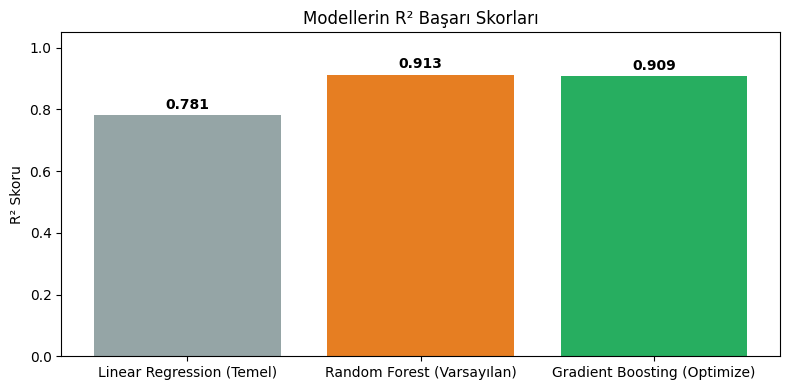

In [10]:
# Model başarılarının grafiği
plt.figure(figsize=(8, 4))
plt.bar(sonuclar['Model'], sonuclar['R² Skoru'], color=['#95a5a6', '#e67e22', '#27ae60'])
plt.title('Modellerin R² Başarı Skorları')
plt.ylabel('R² Skoru')
plt.ylim(0, 1.05)
for i, v in enumerate(sonuclar['R² Skoru']):
    plt.text(i, v + 0.02, f'{v:.3f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Sonuç ve Değerlendirme

- Temel Linear Regression modeli R² olarak yaklaşık %66 civarında kaldı.
- Eğitim seviyesini ordinal yaparak, unvanlardan 'senior' bilgisini çıkararak ve maaşa log dönüşümü uygulayarak Gradient Boosting ile R² skoru %90'ın üzerine çıkarılmıştır.